<a href="https://colab.research.google.com/github/zikaitoh/repos1/blob/master/cnn_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook, we will be creating a CNN (Convolutional Neural Network) based classifier for the classification of CIFAR-10 dataset.

**About the dataset**

CIFAR-10 dataset is a subset of CIFAR-100 having 80 million images of 100 different objects. CIFAR-10 takes 60,000 images for 10 classes from the original dataset in which 50,000 images are for training and 10,000 images are for testing.

The classes in the dataset are -
* airplane
* automobile
* bird
* cat
* deer
* dog
* frog
* horse
* ship
* truck

In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1847s 11us/step


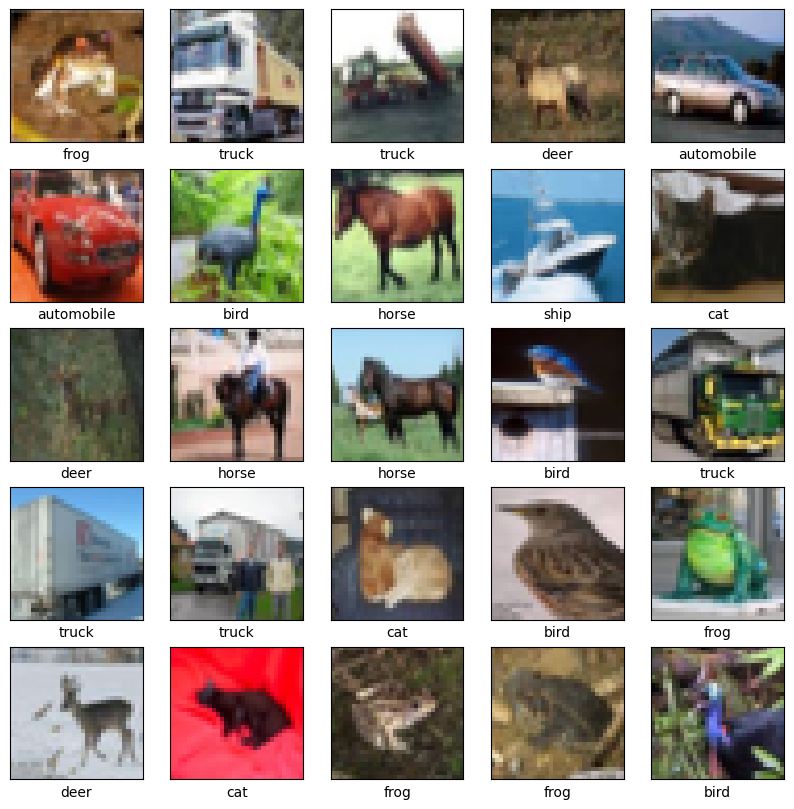

In [8]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

**Creating a CNN model**

We are going to create a CNN based classification model using *keras* module.

In [25]:


def build_model():
    m = models.Sequential([
        layers.Input((32, 32, 3)),

        # Augmentation: only active during training, so inference code is unchanged
        layers.RandomFlip("horizontal"),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomRotation(0.05),


        layers.Conv2D(32, 3, padding='same', use_bias=False),
        layers.BatchNormalization(), layers.Activation('relu'),
        layers.SeparableConv2D(32, 3, padding='same', use_bias=False),
        layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(), layers.Dropout(0.2),

        layers.SeparableConv2D(64, 3, padding='same', use_bias=False),
        layers.BatchNormalization(), layers.Activation('relu'),
        layers.SeparableConv2D(64, 3, padding='same', use_bias=False),
        layers.BatchNormalization(), layers.Activation('relu'),
        layers.MaxPooling2D(), layers.Dropout(0.3),

        layers.SeparableConv2D(128, 3, padding='same', use_bias=False),
        layers.BatchNormalization(), layers.Activation('relu'),
        layers.SeparableConv2D(128, 3, padding='same', use_bias=False),
        layers.BatchNormalization(), layers.Activation('relu'),

        layers.GlobalAveragePooling2D(),   # replaces Flatten + big Dense
        layers.Dropout(0.4),
        layers.Dense(10),
    ])
    m.compile(
      optimizer=tf.keras.optimizers.AdamW(1e-3, weight_decay=1e-4),
      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      metrics=['accuracy'],
      )

    return m

model = build_model()
model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5),
]

history = model.fit(
    train_images, train_labels,
    epochs=40, batch_size=64,
    validation_split=0.1,          # hold out part of TRAIN, not the test set
    callbacks=callbacks,
)

model.evaluate(test_images, test_labels)   # use the test set once, at the end

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_3 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_3            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_15             │ (None, 32, 32, 32)     │         1,312 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_16             │ (None, 16, 16, 64)     │         2,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_20 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_17             │ (None, 16, 16, 64)     │         4,672 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_21 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_18             │ (None, 8, 8, 128)      │         8,768 │
│ (SeparableConv2D)               │                        │             

 Total params: 38,570 (150.66 KB)

 Trainable params: 37,674 (147.16 KB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.3749 - loss: 1.6823 - val_accuracy: 0.4928 - val_loss: 1.3773 - learning_rate: 0.0010
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.4888 - loss: 1.4066 - val_accuracy: 0.4854 - val_loss: 1.4294 - learning_rate: 0.0010
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5335 - loss: 1.2932 - val_accuracy: 0.4566 - val_loss: 1.5399 - learning_rate: 0.0010
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5616 - loss: 1.2231 - val_accuracy: 0.5182 - val_loss: 1.4175 - learning_rate: 0.0010
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5904 - loss: 1.1461 - val_accuracy: 0.5768 - val_loss: 1.2568 - learning_rate: 5.0000e-04
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.6037 - loss: 1.1170 - val_accuracy: 0.5810 - val_loss: 1.2694 - learning_rate: 5.0000e-04
Epoch 7/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.

[0.946071982383728, 0.6647999882698059]

313/313 - 1s - 4ms/step - accuracy: 0.6648 - loss: 0.9461


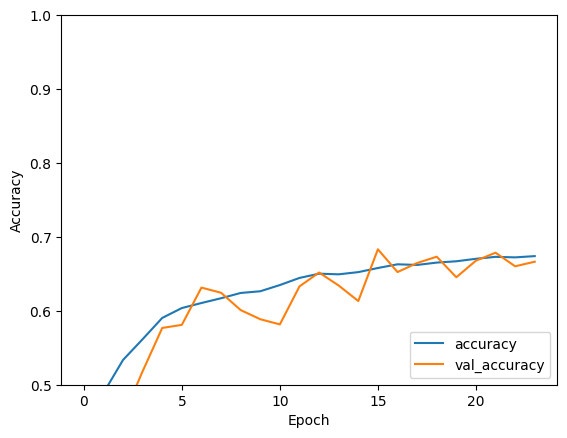

In [28]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

In [ ]:
print(test_acc)

0.6248000264167786


In [6]:
# save model
model.save('final_model.keras') #previously saved as 'final_model.h5", a legacy

In [21]:
# make a prediction for a new image.
from tensorflow.keras import preprocessing
import numpy as np

# load and prepare the image
def load_image(filename):
	# load the image
	img = preprocessing.image.load_img(filename, target_size=(32, 32))
	# convert to array
	img = preprocessing.image.img_to_array(img)
	# reshape into a single sample with 3 channels
	img = img.reshape(1, 32, 32, 3)
	# prepare pixel data
	img = img.astype('float32')
	img = img / 255.0
	return img

# load an image and predict the class
def run_example(sample):
	# load the image
	img = load_image(sample) #upload samples photos in the content folder
	# load model
	model = models.load_model('final_model.keras')
	# predict the class
	pred_list = model.predict(img)
	result = np.argmax(pred_list[0])
	print(sample,":" ,"Prediction:", class_names[result])


# run the example



run_example('cat8.webp')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
cat8.webp : Prediction: frog


cat8.webp : Prediction: frog (49.5%)


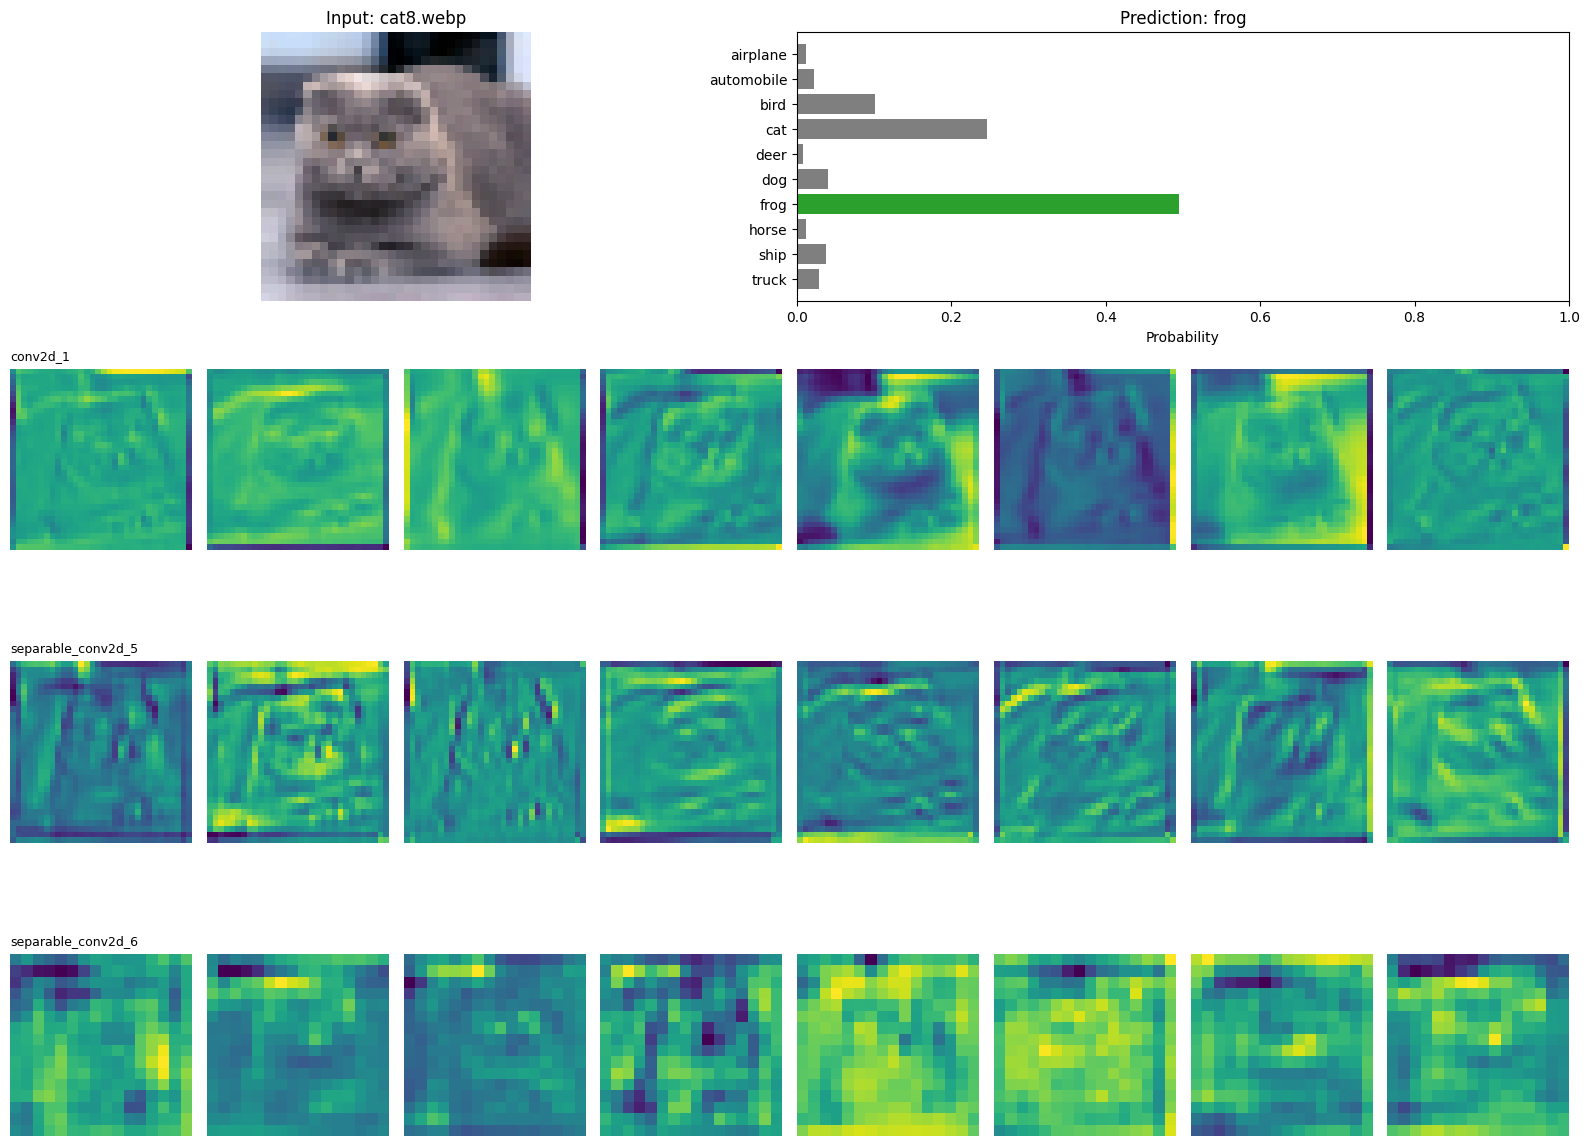

cat9.webp : Prediction: airplane (60.6%)


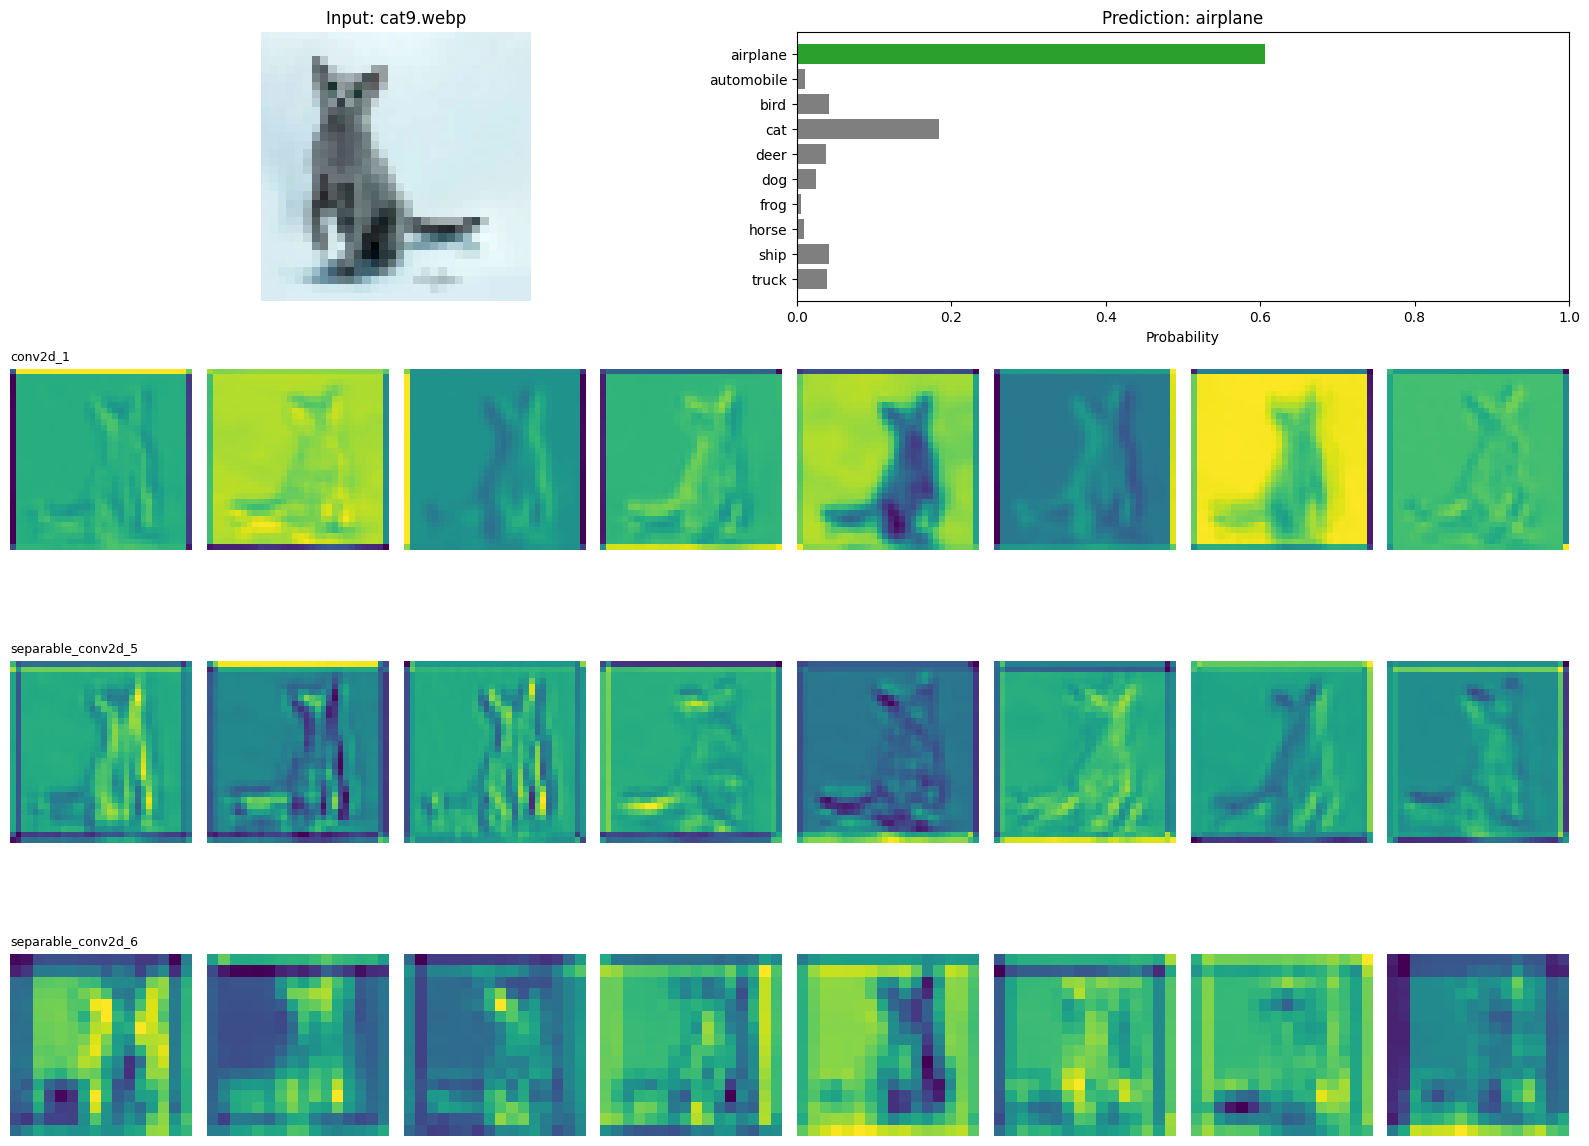

plane1.jpg : Prediction: airplane (99.1%)


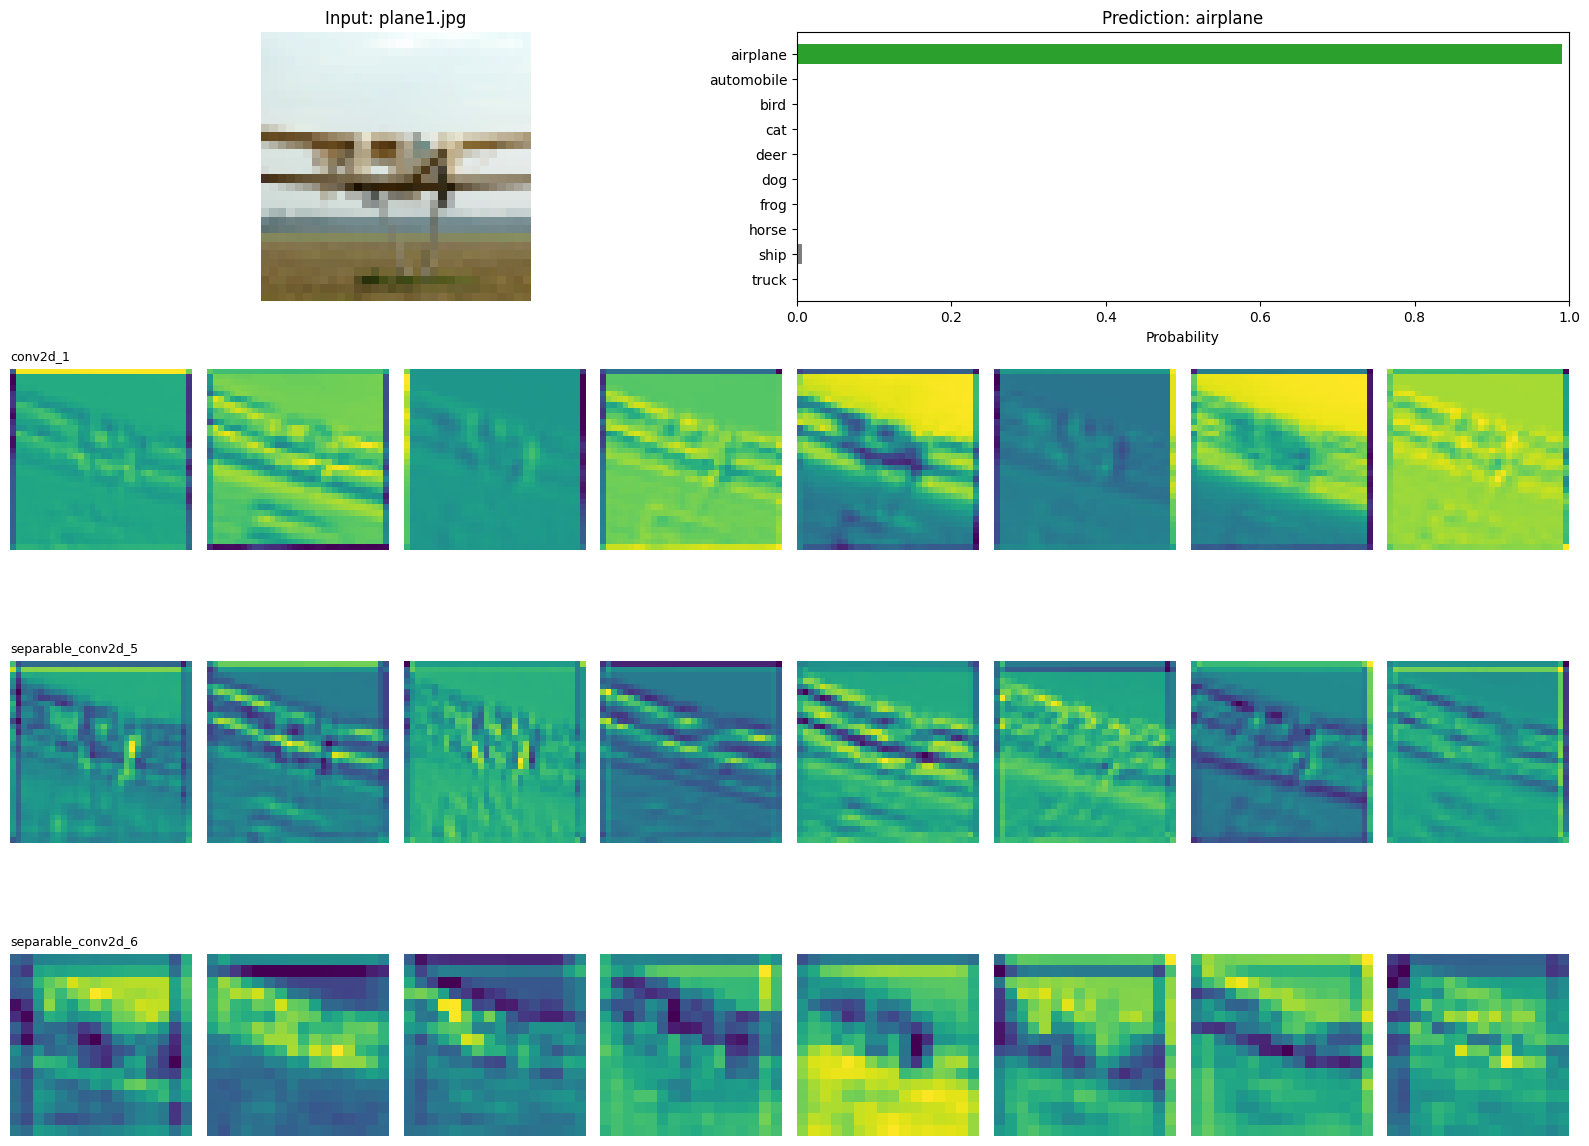

yaeno_muteki.jpg : Prediction: horse (85.1%)


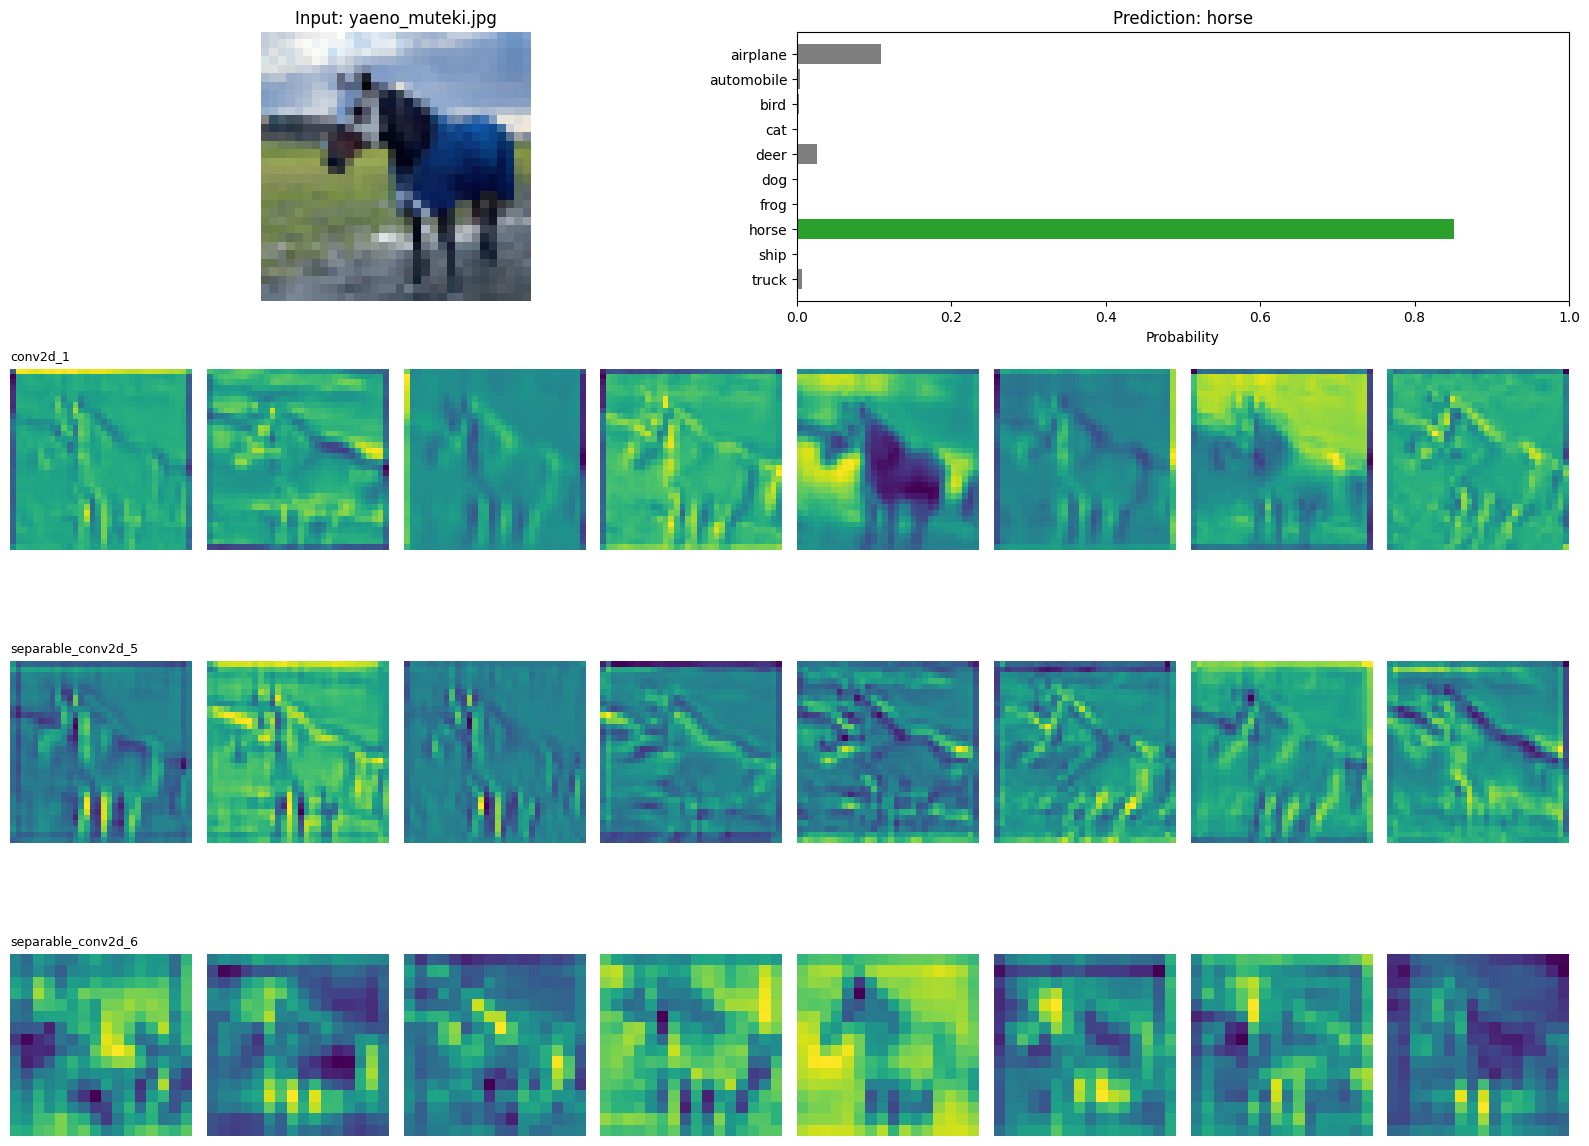

In [22]:
def run_example2(sample, max_layers=3, maps_per_layer=8):
     # load the image
    img = load_image(sample)  # upload sample photos in the content folder
    # load model
    model = models.load_model('final_model.keras')

    # predict the class
    pred_list = model.predict(img, verbose=0)
    probs = pred_list[0]

    # if the output isn't already probabilities, apply softmax  <-- NEW
    if not np.isclose(probs.sum(), 1.0) or probs.min() < 0:
        probs = tf.nn.softmax(probs).numpy()

    result = np.argmax(probs)
    print(sample, ":", "Prediction:", class_names[result], f"({probs[result]:.1%})")

    # run the image through the existing layers, keeping conv outputs
    x = img
    conv_outputs = []
    for layer in model.layers:
        if isinstance(layer, layers.InputLayer):
            continue
        x = layer(x)
        if isinstance(layer, (layers.Conv2D, layers.SeparableConv2D)) and len(conv_outputs) < max_layers:
            conv_outputs.append((layer.name, x.numpy()))

    # layout: top row = image + prediction chart, rows below = feature maps
    n_rows = 1 + len(conv_outputs)
    fig = plt.figure(figsize=(2 * maps_per_layer, 3 * n_rows))
    gs = fig.add_gridspec(n_rows, maps_per_layer)

    # input image
    ax = fig.add_subplot(gs[0, :maps_per_layer // 2])
    show_img = img[0]
    show_img = (show_img - show_img.min()) / (show_img.max() - show_img.min() + 1e-8)
    ax.imshow(show_img.squeeze(), cmap='gray' if show_img.shape[-1] == 1 else None)
    ax.set_title(f"Input: {sample}")
    ax.axis('off')

    # prediction bar chart
    ax = fig.add_subplot(gs[0, maps_per_layer // 2:])
    colors = ['tab:green' if i == result else 'tab:gray' for i in range(len(probs))]
    ax.barh(class_names, probs, color=colors)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Probability")
    ax.set_title(f"Prediction: {class_names[result]}")
    ax.invert_yaxis()

    # what the CNN sees: feature maps from each conv layer
    for row, (name, act) in enumerate(conv_outputs, start=1):
        for col in range(min(maps_per_layer, act.shape[-1])):
            ax = fig.add_subplot(gs[row, col])
            ax.imshow(act[0, :, :, col], cmap='viridis')
            ax.axis('off')
            if col == 0:
                ax.set_title(name, loc='left', fontsize=9)

    plt.tight_layout()
    plt.show()

run_example2('cat8.webp')
run_example2('cat9.webp')
run_example2('plane1.jpg')
run_example2('yaeno_muteki.jpg')